In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/raw/raw/PS_20174392719_1491204439457_log.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (6362620, 11)


In [2]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

print("\nColumn names:")
print(df.columns.tolist())

Rows: 6362620
Columns: 11

Column names:
['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud']


In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 706.2 MB


In [5]:
df.isnull().sum()

step              0
type              0
amount            0
nameOrig          0
oldbalanceOrg     0
newbalanceOrig    0
nameDest          0
oldbalanceDest    0
newbalanceDest    0
isFraud           0
isFlaggedFraud    0
dtype: int64

In [6]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [7]:
fraud_counts = df["isFraud"].value_counts()

print(fraud_counts)

print("\nFraud percentage:")
print(df["isFraud"].value_counts(normalize=True) * 100)

isFraud
0    6354407
1       8213
Name: count, dtype: int64

Fraud percentage:
isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64


In [8]:
print(df["type"].value_counts())

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64


In [9]:
fraud_by_type = pd.crosstab(
    df["type"],
    df["isFraud"],
    normalize="index"
) * 100

print(fraud_by_type)

isFraud            0         1
type                          
CASH_IN   100.000000  0.000000
CASH_OUT   99.816045  0.183955
DEBIT     100.000000  0.000000
PAYMENT   100.000000  0.000000
TRANSFER   99.231201  0.768799


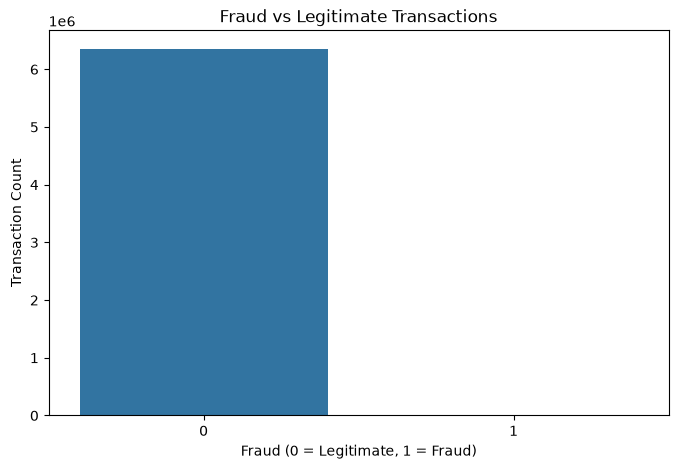

In [10]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x="isFraud"
)

plt.title("Fraud vs Legitimate Transactions")
plt.xlabel("Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Count")

plt.show()

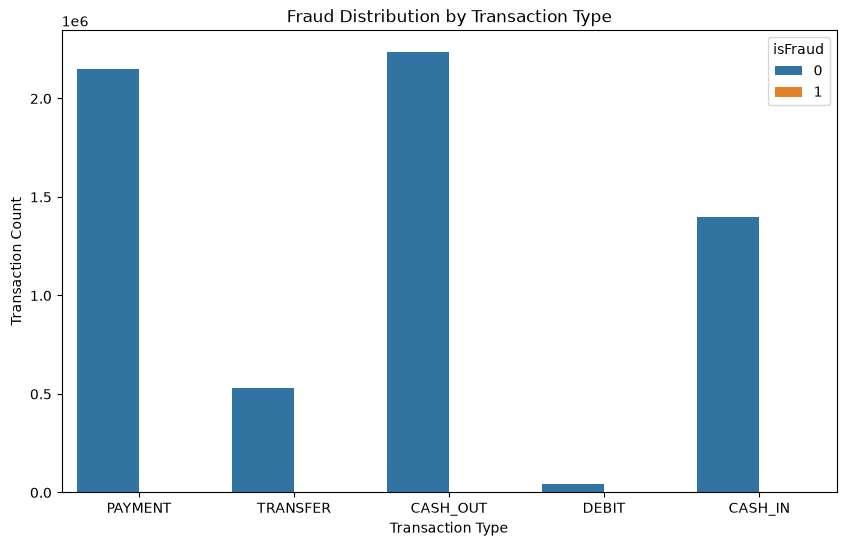

In [11]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x="type",
    hue="isFraud"
)

plt.title("Fraud Distribution by Transaction Type")
plt.xlabel("Transaction Type")
plt.ylabel("Transaction Count")

plt.show()

# Stage 2 — Fraud Investigation & Leakage Audit

The objective of this stage is to determine:

1. Which fields are available before transaction authorization?
2. Which fields are generated after the transaction?
3. Which fields can create target leakage?
4. Which transaction behaviors are strongly associated with fraud?
5. Which features can safely be used by our production model?

In [12]:
for column in df.columns:
    print(column)

step
type
amount
nameOrig
oldbalanceOrg
newbalanceOrig
nameDest
oldbalanceDest
newbalanceDest
isFraud
isFlaggedFraud


In [13]:
fraud_df = df[df["isFraud"] == 1]

print("Fraud transactions:", len(fraud_df))
print("Fraud transaction types:")
print(fraud_df["type"].value_counts())

Fraud transactions: 8213
Fraud transaction types:
type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64


In [14]:
df.groupby("isFraud")["amount"].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


In [15]:
fraud_rate_by_type = (
    df.groupby("type")["isFraud"]
      .agg(["count", "sum", "mean"])
      .sort_values("mean", ascending=False)
)

fraud_rate_by_type["fraud_rate_percent"] = (
    fraud_rate_by_type["mean"] * 100
)

fraud_rate_by_type

,count,sum,mean,fraud_rate_percent
type,,,,
TRANSFER,532909,4097,0.007688,0.768799
CASH_OUT,2237500,4116,0.001840,0.183955
CASH_IN,1399284,0,0.000000,0.000000
DEBIT,41432,0,0.000000,0.000000
PAYMENT,2151495,0,0.000000,0.000000


In [16]:
pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"],
    margins=True
)

isFraud,0,1,All
isFlaggedFraud,,,
0,6354407,8197,6362604
1,0,16,16
All,6354407,8213,6362620


In [17]:
print(
    pd.crosstab(
        df["isFlaggedFraud"],
        df["isFraud"],
        normalize="index"
    ) * 100
)

isFraud                 0           1
isFlaggedFraud                       
0               99.871169    0.128831
1                0.000000  100.000000


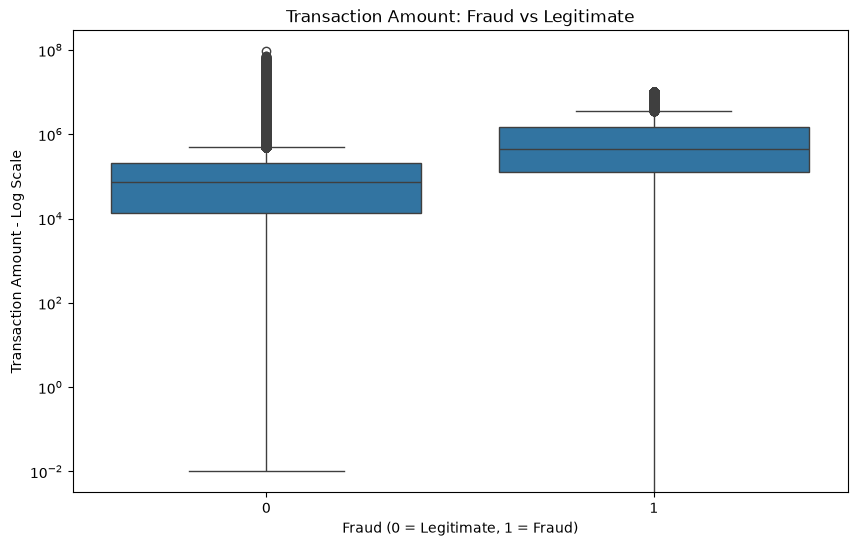

In [18]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="isFraud",
    y="amount"
)

plt.yscale("log")

plt.title("Transaction Amount: Fraud vs Legitimate")
plt.xlabel("Fraud (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Transaction Amount - Log Scale")

plt.show()

In [19]:
df["orig_balance_change"] = (
    df["oldbalanceOrg"] - df["newbalanceOrig"]
)

df["dest_balance_change"] = (
    df["newbalanceDest"] - df["oldbalanceDest"]
)

In [20]:
df[
    [
        "amount",
        "oldbalanceOrg",
        "newbalanceOrig",
        "orig_balance_change",
        "oldbalanceDest",
        "newbalanceDest",
        "dest_balance_change"
    ]
].head(10)

,amount,oldbalanceOrg,newbalanceOrig,orig_balance_change,oldbalanceDest,newbalanceDest,dest_balance_change
0,9839.64,170136.00,160296.36,9839.64,0.0,0.00,0.00
1,1864.28,21249.00,19384.72,1864.28,0.0,0.00,0.00
2,181.00,181.00,0.00,181.00,0.0,0.00,0.00
3,181.00,181.00,0.00,181.00,21182.0,0.00,-21182.00
4,11668.14,41554.00,29885.86,11668.14,0.0,0.00,0.00
5,7817.71,53860.00,46042.29,7817.71,0.0,0.00,0.00
6,7107.77,183195.00,176087.23,7107.77,0.0,0.00,0.00
7,7861.64,176087.23,168225.59,7861.64,0.0,0.00,0.00
8,4024.36,2671.00,0.00,2671.00,0.0,0.00,0.00
9,5337.77,41720.00,36382.23,5337.77,41898.0,40348.79,-1549.21


In [21]:
df["orig_amount_difference"] = (
    df["amount"] - df["orig_balance_change"]
)

df["dest_amount_difference"] = (
    df["amount"] - df["dest_balance_change"]
)

df[
    [
        "amount",
        "orig_balance_change",
        "orig_amount_difference",
        "dest_balance_change",
        "dest_amount_difference"
    ]
].describe()

,amount,orig_balance_change,orig_amount_difference,dest_balance_change,dest_amount_difference
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,1.798619e+05,-2.123056e+04,2.010925e+05,1.242947e+05,5.556717e+04
std,6.038582e+05,1.466433e+05,6.066505e+05,8.129391e+05,4.415288e+05
min,0.000000e+00,-1.915268e+06,-1.000000e-02,-1.306083e+07,-7.588573e+07
25%,1.338957e+04,0.000000e+00,2.954230e+03,0.000000e+00,0.000000e+00
50%,7.487194e+04,0.000000e+00,6.867726e+04,0.000000e+00,3.500490e+03
75%,2.087215e+05,1.015044e+04,2.496411e+05,1.491054e+05,2.935305e+04
max,9.244552e+07,1.000000e+07,9.244552e+07,1.056878e+08,1.319123e+07


In [22]:
df.groupby("isFraud")[
    [
        "amount",
        "orig_balance_change",
        "dest_balance_change"
    ]
].mean()

,amount,orig_balance_change,dest_balance_change
isFraud,,,
0,1.781970e+05,-2.314152e+04,123504.809994
1,1.467967e+06,1.457275e+06,735457.998071


In [23]:
df.groupby("isFraud")[
    [
        "amount",
        "orig_balance_change",
        "dest_balance_change"
    ]
].median()

,amount,orig_balance_change,dest_balance_change
isFraud,,,
0,74684.72,0.00,0.0
1,441423.44,436317.49,0.0


In [24]:
df["amount_equals_oldbalance"] = (
    np.isclose(
        df["amount"],
        df["oldbalanceOrg"]
    )
)

pd.crosstab(
    df["amount_equals_oldbalance"],
    df["isFraud"],
    normalize="index"
) * 100

isFraud,0,1
amount_equals_oldbalance,,
False,99.997183,0.002817
True,0.087054,99.912946


In [25]:
df.groupby("amount_equals_oldbalance")["isFraud"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
amount_equals_oldbalance,,,
False,6354579,179,0.000028
True,8041,8034,0.999129


## Feature Availability Audit

### Safe at authorization time

- step
- type
- amount
- nameOrig
- nameDest
- oldbalanceOrg
- oldbalanceDest

### Post-transaction / potentially unavailable

- newbalanceOrig
- newbalanceDest

### Target / cannot be used as model input

- isFraud

### Existing rule signal requiring investigation

- isFlaggedFraud

In [26]:
fraud_df["type"].value_counts()

type
CASH_OUT    4116
TRANSFER    4097
Name: count, dtype: int64

In [27]:
fraud_rate_by_type

,count,sum,mean,fraud_rate_percent
type,,,,
TRANSFER,532909,4097,0.007688,0.768799
CASH_OUT,2237500,4116,0.001840,0.183955
CASH_IN,1399284,0,0.000000,0.000000
DEBIT,41432,0,0.000000,0.000000
PAYMENT,2151495,0,0.000000,0.000000


In [28]:
pd.crosstab(
    df["isFlaggedFraud"],
    df["isFraud"],
    normalize="index"
) * 100

isFraud,0,1
isFlaggedFraud,,
0,99.871169,0.128831
1,0.000000,100.000000


In [29]:
df.groupby("isFraud")[
    ["amount", "orig_balance_change", "dest_balance_change"]
].mean()

,amount,orig_balance_change,dest_balance_change
isFraud,,,
0,1.781970e+05,-2.314152e+04,123504.809994
1,1.467967e+06,1.457275e+06,735457.998071


In [30]:
df.groupby("amount_equals_oldbalance")["isFraud"].agg(
    ["count", "sum", "mean"]
)

,count,sum,mean
amount_equals_oldbalance,,,
False,6354579,179,0.000028
True,8041,8034,0.999129


In [31]:
features = df.copy()

print("Feature dataframe shape:", features.shape)

Feature dataframe shape: (6362620, 16)


In [32]:
features["amount_log"] = np.log1p(features["amount"])

In [33]:
features["amount_to_origin_balance"] = np.where(
    features["oldbalanceOrg"] > 0,
    features["amount"] / features["oldbalanceOrg"],
    0
)

In [34]:
features["origin_balance_remaining_ratio"] = np.where(
    features["oldbalanceOrg"] > 0,
    features["newbalanceOrig"] / features["oldbalanceOrg"],
    0
)

In [35]:
features["amount_to_dest_balance"] = np.where(
    features["oldbalanceDest"] > 0,
    features["amount"] / features["oldbalanceDest"],
    0
)

In [36]:
features["origin_balance_depletion"] = (
    features["amount"] >= features["oldbalanceOrg"]
).astype(int)

In [37]:
features["origin_balance_zero"] = (
    features["oldbalanceOrg"] == 0
).astype(int)

In [38]:
features["destination_balance_zero"] = (
    features["oldbalanceDest"] == 0
).astype(int)

In [39]:
features["amount_minus_origin_balance"] = (
    features["amount"] - features["oldbalanceOrg"]
)

In [40]:
features["amount_exceeds_origin_balance"] = (
    features["amount"] > features["oldbalanceOrg"]
).astype(int)

In [41]:
features["type"].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [42]:
print("Minimum step:", features["step"].min())
print("Maximum step:", features["step"].max())
print("Unique steps:", features["step"].nunique())

Minimum step: 1
Maximum step: 743
Unique steps: 743


In [43]:
features["hour"] = features["step"] % 24

In [44]:
features["day"] = features["step"] // 24

In [45]:
features["hour_sin"] = np.sin(
    2 * np.pi * features["hour"] / 24
)

features["hour_cos"] = np.cos(
    2 * np.pi * features["hour"] / 24
)

In [46]:
features = features.sort_values(
    ["step"]
).reset_index(drop=True)

In [47]:
features[["step", "type", "amount"]].head(20)

,step,type,amount
0,1,PAYMENT,9839.64
1,1,PAYMENT,1864.28
2,1,TRANSFER,181.00
3,1,CASH_OUT,181.00
4,1,PAYMENT,11668.14
5,1,PAYMENT,7817.71
6,1,PAYMENT,7107.77
7,1,PAYMENT,7861.64
8,1,PAYMENT,4024.36
9,1,DEBIT,5337.77


In [48]:
features["transaction_index"] = np.arange(
    len(features)
)

In [49]:
features["prev_origin_amount"] = (
    features.groupby("nameOrig")["amount"]
    .shift(1)
)

In [50]:
features["prev_origin_amount"] = (
    features["prev_origin_amount"]
    .fillna(0)
)

In [51]:
features["prev_origin_type"] = (
    features.groupby("nameOrig")["type"]
    .shift(1)
)

In [52]:
features["prev_dest_amount"] = (
    features.groupby("nameDest")["amount"]
    .shift(1)
)

features["prev_dest_amount"] = (
    features["prev_dest_amount"].fillna(0)
)

In [53]:
features["origin_transaction_count"] = (
    features.groupby("nameOrig")
    .cumcount()
)

In [54]:
features["destination_transaction_count"] = (
    features.groupby("nameDest")
    .cumcount()
)

In [55]:
features["amount_vs_previous_origin"] = np.where(
    features["prev_origin_amount"] > 0,
    features["amount"] / features["prev_origin_amount"],
    0
)

In [56]:
feature_columns = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "amount_log",
    "amount_to_origin_balance",
    "amount_to_dest_balance",
    "origin_balance_depletion",
    "origin_balance_zero",
    "destination_balance_zero",
    "hour",
    "day",
    "hour_sin",
    "hour_cos",
    "prev_origin_amount",
    "prev_dest_amount",
    "origin_transaction_count",
    "destination_transaction_count",
    "amount_vs_previous_origin",
    "isFraud"
]

features[feature_columns].head(20)

,step,type,amount,oldbalanceOrg,oldbalanceDest,amount_log,amount_to_origin_balance,amount_to_dest_balance,origin_balance_depletion,origin_balance_zero,...,hour,day,hour_sin,hour_cos,prev_origin_amount,prev_dest_amount,origin_transaction_count,destination_transaction_count,amount_vs_previous_origin,isFraud
0,1,PAYMENT,9839.64,170136.00,0.0,9.194276,0.057834,0.000000,0,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,0
1,1,PAYMENT,1864.28,21249.00,0.0,7.531166,0.087735,0.000000,0,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,0
2,1,TRANSFER,181.00,181.00,0.0,5.204007,1.000000,0.000000,1,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,1
3,1,CASH_OUT,181.00,181.00,21182.0,5.204007,1.000000,0.008545,1,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,1
4,1,PAYMENT,11668.14,41554.00,0.0,9.364703,0.280795,0.000000,0,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,0
5,1,PAYMENT,7817.71,53860.00,0.0,8.964275,0.145149,0.000000,0,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,0
6,1,PAYMENT,7107.77,183195.00,0.0,8.869085,0.038799,0.000000,0,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,0
7,1,PAYMENT,7861.64,176087.23,0.0,8.969878,0.044646,0.000000,0,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,0
8,1,PAYMENT,4024.36,2671.00,0.0,8.300370,1.506687,0.000000,1,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,0
9,1,DEBIT,5337.77,41720.00,41898.0,8.582751,0.127943,0.127399,0,0,...,1,0,0.258819,0.965926,0.0,0.0,0,0,0.0,0


In [57]:
print(
    "NaN values:",
    features[feature_columns].isna().sum().sum()
)

print(
    "Infinite values:",
    np.isinf(
        features.select_dtypes(include=np.number)
    ).sum().sum()
)

NaN values: 0
Infinite values: 0


In [58]:
processed_path = "../data/processed/authorization_features_v1.csv"

features.to_csv(
    processed_path,
    index=False
)

print("Saved:", processed_path)

Saved: ../data/processed/authorization_features_v1.csv


# Stage 4 — Modeling Dataset

The first model uses only features that are available at or before transaction authorization.

Post-transaction balance fields and raw account identifiers are excluded.

In [3]:
import pandas as pd
import numpy as np

features = pd.read_csv(
    "../data/processed/authorization_features_v1.csv"
)

print("Features loaded successfully!")
print("Shape:", features.shape)

C:\Users\heman\AppData\Local\Temp\ipykernel_34372\3128052716.py:4: DtypeWarning: Columns (0: prev_origin_type) have mixed types. Specify dtype option on import or set low_memory=False.
  features = pd.read_csv(


Features loaded successfully!
Shape: (6362620, 36)


In [4]:
print(features.columns.tolist())

['step', 'type', 'amount', 'nameOrig', 'oldbalanceOrg', 'newbalanceOrig', 'nameDest', 'oldbalanceDest', 'newbalanceDest', 'isFraud', 'isFlaggedFraud', 'orig_balance_change', 'dest_balance_change', 'orig_amount_difference', 'dest_amount_difference', 'amount_equals_oldbalance', 'amount_log', 'amount_to_origin_balance', 'origin_balance_remaining_ratio', 'amount_to_dest_balance', 'origin_balance_depletion', 'origin_balance_zero', 'destination_balance_zero', 'amount_minus_origin_balance', 'amount_exceeds_origin_balance', 'hour', 'day', 'hour_sin', 'hour_cos', 'transaction_index', 'prev_origin_amount', 'prev_origin_type', 'prev_dest_amount', 'origin_transaction_count', 'destination_transaction_count', 'amount_vs_previous_origin']


In [5]:
features.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,...,day,hour_sin,hour_cos,transaction_index,prev_origin_amount,prev_origin_type,prev_dest_amount,origin_transaction_count,destination_transaction_count,amount_vs_previous_origin
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,...,0,0.258819,0.965926,0,0.0,NaN,0.0,0,0,0.0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,...,0,0.258819,0.965926,1,0.0,NaN,0.0,0,0,0.0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,...,0,0.258819,0.965926,2,0.0,NaN,0.0,0,0,0.0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,...,0,0.258819,0.965926,3,0.0,NaN,0.0,0,0,0.0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,...,0,0.258819,0.965926,4,0.0,NaN,0.0,0,0,0.0


In [6]:
model_features = [
    "step",
    "type",
    "amount",
    "oldbalanceOrg",
    "oldbalanceDest",
    "amount_log",
    "amount_to_origin_balance",
    "amount_to_dest_balance",
    "origin_balance_depletion",
    "origin_balance_zero",
    "destination_balance_zero",
    "hour",
    "day",
    "hour_sin",
    "hour_cos"
]

target = "isFraud"

model_df = features[
    model_features + [target]
].copy()

print("Model dataset shape:", model_df.shape)

Model dataset shape: (6362620, 16)


In [7]:
print(model_df.columns.tolist())

['step', 'type', 'amount', 'oldbalanceOrg', 'oldbalanceDest', 'amount_log', 'amount_to_origin_balance', 'amount_to_dest_balance', 'origin_balance_depletion', 'origin_balance_zero', 'destination_balance_zero', 'hour', 'day', 'hour_sin', 'hour_cos', 'isFraud']


In [8]:
print(model_df.head())

   step      type    amount  oldbalanceOrg  oldbalanceDest  amount_log  \
0     1   PAYMENT   9839.64       170136.0             0.0    9.194276   
1     1   PAYMENT   1864.28        21249.0             0.0    7.531166   
2     1  TRANSFER    181.00          181.0             0.0    5.204007   
3     1  CASH_OUT    181.00          181.0         21182.0    5.204007   
4     1   PAYMENT  11668.14        41554.0             0.0    9.364703   

   amount_to_origin_balance  amount_to_dest_balance  origin_balance_depletion  \
0                  0.057834                0.000000                         0   
1                  0.087735                0.000000                         0   
2                  1.000000                0.000000                         1   
3                  1.000000                0.008545                         1   
4                  0.280795                0.000000                         0   

   origin_balance_zero  destination_balance_zero  hour  day  hour_si

In [9]:
print(model_df["isFraud"].value_counts())

isFraud
0    6354407
1       8213
Name: count, dtype: int64


In [10]:
print("Missing values:")
print(model_df.isnull().sum())

Missing values:
step                        0
type                        0
amount                      0
oldbalanceOrg               0
oldbalanceDest              0
amount_log                  0
amount_to_origin_balance    0
amount_to_dest_balance      0
origin_balance_depletion    0
origin_balance_zero         0
destination_balance_zero    0
hour                        0
day                         0
hour_sin                    0
hour_cos                    0
isFraud                     0
dtype: int64


In [11]:
print("Infinite values:")

print(
    np.isinf(
        model_df.select_dtypes(
            include=np.number
        )
    ).sum()
)

Infinite values:
step                        0
amount                      0
oldbalanceOrg               0
oldbalanceDest              0
amount_log                  0
amount_to_origin_balance    0
amount_to_dest_balance      0
origin_balance_depletion    0
origin_balance_zero         0
destination_balance_zero    0
hour                        0
day                         0
hour_sin                    0
hour_cos                    0
isFraud                     0
dtype: int64


In [12]:
unique_steps = np.sort(
    model_df["step"].unique()
)

train_cutoff = int(
    len(unique_steps) * 0.70
)

validation_cutoff = int(
    len(unique_steps) * 0.85
)

train_steps = unique_steps[:train_cutoff]

validation_steps = unique_steps[
    train_cutoff:validation_cutoff
]

test_steps = unique_steps[
    validation_cutoff:
]

print("Training steps:", len(train_steps))
print("Validation steps:", len(validation_steps))
print("Test steps:", len(test_steps))

Training steps: 520
Validation steps: 111
Test steps: 112


In [13]:
train_df = model_df[
    model_df["step"].isin(train_steps)
].copy()

validation_df = model_df[
    model_df["step"].isin(validation_steps)
].copy()

test_df = model_df[
    model_df["step"].isin(test_steps)
].copy()

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Train: (6082007, 16)
Validation: (191147, 16)
Test: (89466, 16)


In [14]:
print(
    "Train:",
    train_df["step"].min(),
    "->",
    train_df["step"].max()
)

print(
    "Validation:",
    validation_df["step"].min(),
    "->",
    validation_df["step"].max()
)

print(
    "Test:",
    test_df["step"].min(),
    "->",
    test_df["step"].max()
)

Train: 1 -> 520
Validation: 521 -> 631
Test: 632 -> 743


In [15]:
print("TRAIN")
print(y_train.value_counts() if "y_train" in globals() else train_df["isFraud"].value_counts())

print("\nVALIDATION")
print(validation_df["isFraud"].value_counts())

print("\nTEST")
print(test_df["isFraud"].value_counts())

TRAIN
isFraud
0    6076226
1       5781
Name: count, dtype: int64

VALIDATION
isFraud
0    189967
1      1180
Name: count, dtype: int64

TEST
isFraud
0    88214
1     1252
Name: count, dtype: int64


In [16]:
train_df.to_csv(
    "../data/processed/train.csv",
    index=False
)

validation_df.to_csv(
    "../data/processed/validation.csv",
    index=False
)

test_df.to_csv(
    "../data/processed/test.csv",
    index=False
)

print("✅ Train, validation and test datasets saved!")

✅ Train, validation and test datasets saved!
